⚠️ **IMPORTANT**: Since `conda init` was already run and likely configured your shell environment, you now **must** restart your Colab runtime (`Runtime` -> `Restart runtime...`). After the runtime restarts, you can then proceed to create and activate your environment.

In [1]:
# claudio-i@ace.me

In [94]:
import numpy as np
import pandas as pd
from scipy.io import loadmat
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import savgol_filter

import os
import glob
import xarray as xr

In [95]:
cd /home/cl/Google/@doctorado-sync/database/hycom-sim


/home/cl/Google/@doctorado-sync/database/hycom-sim


In [96]:
pwd

'/home/cl/Google/@doctorado-sync/database/hycom-sim'

In [97]:
#Map

In [98]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import matplotlib.cm as cm
import matplotlib.colors as colors

In [99]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import cartopy.crs as ccrs
import cartopy.feature as cfeature
# ---------------------------------------------------------
# Preprocess function to fix your "time(one)" structure
# ---------------------------------------------------------
def preprocess(ds):
    ds = ds.load()  # force load so we can safely manipulate variables

    # Extract time from the data variable "time(one)"
    if "time" in ds.data_vars:
        t = ds["time"].values

        # Take the scalar datetime (array of length 1)
        t = pd.to_datetime(np.asarray(t).ravel()[0])

        # Drop the old time variable
        ds = ds.drop_vars("time")

        # Remove the "one" dimension
        if "one" in ds.dims:
            ds = ds.squeeze("one", drop=True)

        # Add a proper "time" coordinate with a new dimension
        ds = ds.expand_dims(time=[t])

    else:
        raise ValueError("This dataset does not contain a 'time' variable.")

    return ds

In [100]:
# ---------------------------------------------------------
# Collect all .nc files (adjust pattern if needed)
# ---------------------------------------------------------
files = sorted(glob.glob("/home/cl/Google/@doctorado-sync/database/hycom-l1/2020/files/01/W*.nc"))
print(f"Found {len(files)} files.")


# ---------------------------------------------------------
# Concatenate using open_mfdataset + preprocess
# ---------------------------------------------------------
ds_all01 = xr.open_mfdataset(
    files,
    combine="nested",
    concat_dim="time",
    preprocess=preprocess,
    parallel=False,     # set True if you want Dask parallelism
    decode_times=True
)

# Sort times just in case
ds_all01 = ds_all01.sortby("time")

Found 248 files.


/tmp/ipykernel_22334/1496647585.py:45: RuntimeWarning: Mean of empty slice
  np.nanmean(ds_all01['temp'][:,0,:,:], axis = 0),


Text(0.5, 1.0, '100-km Radial Transects')

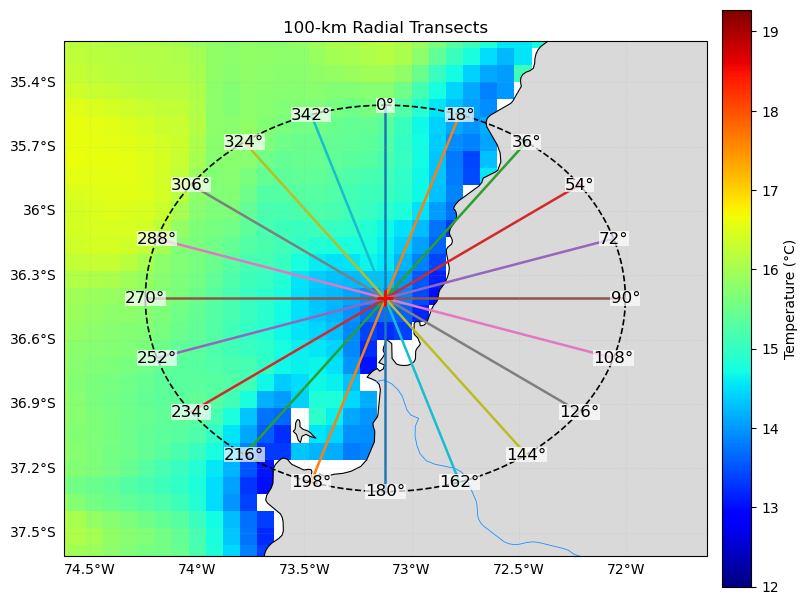

In [101]:
center_x = -73.1224
center_y = -36.4075
center_lon = center_x
center_lat = center_y

radius_km = 100.0          # Distance from center in kilometers
num_angles = 20             # Number of directions (0°, 45°, 90°, etc.)
num_points_per_line = 100  # Resolution along each radial transect

# Generate angles (0° = North, 90° = East, 180° = South, 270° = West)
angles_deg = np.linspace(0, 360, num_angles, endpoint=False)
distances_km = np.linspace(0, radius_km, num_points_per_line)

# Approximate coordinate conversion near center_lat
km_per_deg_lat = 111.0
km_per_deg_lon = 111.0 * np.cos(np.radians(center_lat))

# Create 2D coordinate grids (angle x distance)
angles_grid = angles_deg[:, np.newaxis]
dist_grid = distances_km[np.newaxis, :]

# Calculate Longitudes and Latitudes for all radial points
d_lat = (dist_grid * np.cos(np.radians(angles_grid))) / km_per_deg_lat
d_lon = (dist_grid * np.sin(np.radians(angles_grid))) / km_per_deg_lon

target_lons = center_lon + d_lon
target_lats = center_lat + d_lat



# ==============================================================================
# MAP VIEW
# ==============================================================================
crs = ccrs.PlateCarree()

fig = plt.figure(figsize=(10,10))
ax = plt.axes(projection=crs)

# --------------------------------------------------------------------------
# SST
# --------------------------------------------------------------------------
mesh = ax.pcolormesh(
    ds_all01.lon,
    ds_all01.lat,
    np.nanmean(ds_all01['temp'][:,0,:,:], axis = 0),
    cmap='jet',
    shading='auto',
    transform=crs,
    zorder=0
)

plt.colorbar(mesh, ax=ax, shrink=0.75, pad=0.02,
             label='Temperature (°C)')

# --------------------------------------------------------------------------
# Land, Coastline and Rivers
# --------------------------------------------------------------------------
ax.add_feature(cfeature.LAND, facecolor='0.85', zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale('10m'), linewidth=0.8, zorder=2)

ax.add_feature(
    cfeature.NaturalEarthFeature(
        'physical',
        'rivers_lake_centerlines',
        '10m',
        edgecolor='dodgerblue',
        facecolor='none'),
    linewidth=0.6,
    zorder=2
)

# --------------------------------------------------------------------------
# 100-km circle
# --------------------------------------------------------------------------
theta = np.linspace(0,2*np.pi,300)

circle_lon = center_lon + radius_km*np.sin(theta)/km_per_deg_lon
circle_lat = center_lat + radius_km*np.cos(theta)/km_per_deg_lat

ax.plot(circle_lon,
        circle_lat,
        '--k',
        lw=1.2,
        transform=crs)

# --------------------------------------------------------------------------
# Radial transects
# --------------------------------------------------------------------------
for i, ang in enumerate(angles_deg):

    ax.plot(target_lons[i],
            target_lats[i],
            lw=1.8,
            transform=crs)

    # angle label at the end of each transect
    ax.text(target_lons[i,-1],
            target_lats[i,-1],
            f'{int(ang)}°',
            fontsize=12,
            ha='center',
            va='center',
            transform=crs,
            bbox=dict(fc='white',
                      ec='none',
                      alpha=0.7,
                      pad=0.15))

# --------------------------------------------------------------------------
# Station
# --------------------------------------------------------------------------
ax.plot(center_lon,
        center_lat,
        '+r',
        ms=12,
        mew=2,
        transform=crs,
        zorder=5)

ax.set_extent([center_lon-1.5,
               center_lon+1.5,
               center_lat-1.2,
               center_lat+1.2])

gl = ax.gridlines(draw_labels=True,
                  linewidth=0.4,
                  linestyle=':',
                  alpha=0.5)

gl.top_labels = False
gl.right_labels = False

ax.set_title('100-km Radial Transects')

In [102]:
del ds_all01

In [103]:
#

In [104]:
# 1. Load the specific angle Dataset from the saved NetCDF file
file_path = "./radial_sections/section_angle_018deg_01.nc"
dsX01_1 = xr.open_dataset(file_path)
dsX01_1_mean = dsX01_1.mean(dim="time")
dsX01_1_daily = dsX01_1.resample(time='1D').mean()

file_path = "./radial_sections/section_angle_342deg_01.nc"
dsX01_2 = xr.open_dataset(file_path)
dsX01_2_mean = dsX01_2.mean(dim="time")
dsX01_2_daily = dsX01_2.resample(time='1D').mean()

file_path = "./radial_sections/section_angle_306deg_01.nc"
dsX01_3 = xr.open_dataset(file_path)
dsX01_3_mean = dsX01_3.mean(dim="time")
dsX01_3_daily = dsX01_3.resample(time='1D').mean()

file_path = "./radial_sections/section_angle_252deg_01.nc"
dsX01_4 = xr.open_dataset(file_path)
dsX01_4_mean = dsX01_4.mean(dim="time")
dsX01_4_daily = dsX01_4.resample(time='1D').mean()

file_path = "./radial_sections/section_angle_216deg_01.nc"
dsX01_5 = xr.open_dataset(file_path)
dsX01_5_mean = dsX01_5.mean(dim="time")
dsX01_5_daily = dsX01_5.resample(time='1D').mean()

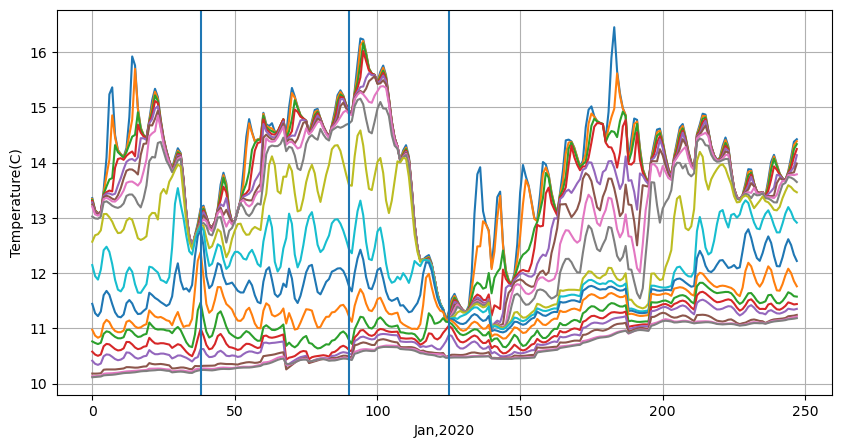

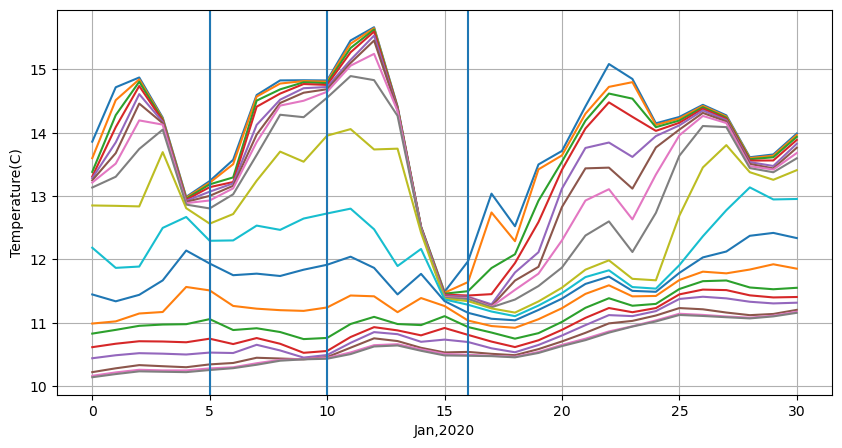

In [105]:
plt.figure(figsize=(10,5))
for i in range(0,20):
    plt.plot(dsX01_1['temp'][:,i,0])
plt.ylabel('Temperature(C)')
plt.xlabel('Jan,2020')
plt.axvline(38)
plt.axvline(90)
plt.axvline(125)
plt.grid()

#---------------------------------
#---------------------------------

plt.figure(figsize=(10,5))
for i in range(0,20):
    plt.plot(dsX01_1_daily['temp'][:,i,0])
plt.ylabel('Temperature(C)')
plt.xlabel('Jan,2020')
plt.axvline(5)
plt.axvline(10)
plt.axvline(16)
plt.grid()

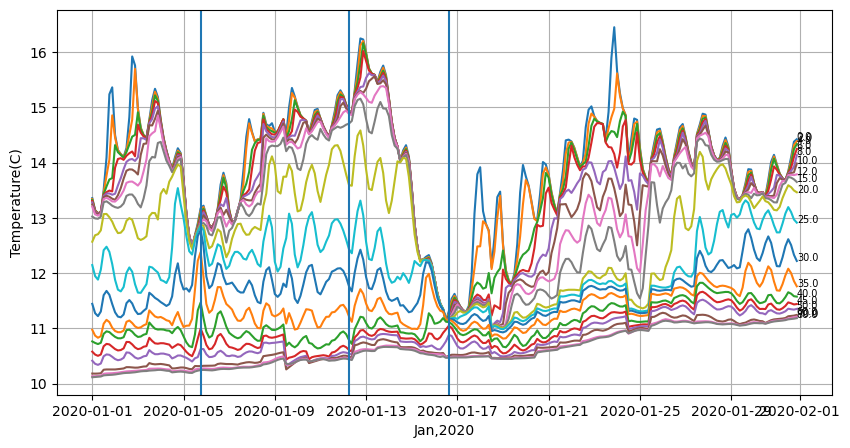

In [106]:
plt.figure(figsize=(10,5))
for i in range(0,20):
    plt.plot(dsX01_1['time'],dsX01_1['temp'][:,i,0])
    plt.text(dsX01_1['time'][-1],dsX01_1['temp'][-1,i,0], dsX01_1['depth'][i].values, fontsize = 7)
plt.ylabel('Temperature(C)')
plt.xlabel('Jan,2020')
plt.grid()
plt.axvline(dsX01_1['time'][38].values)
plt.axvline(dsX01_1['time'][90].values)
plt.axvline(dsX01_1['time'][125].values)

In [107]:
#

In [108]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects
from scipy.ndimage import gaussian_filter


/tmp/ipykernel_22334/1298562672.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


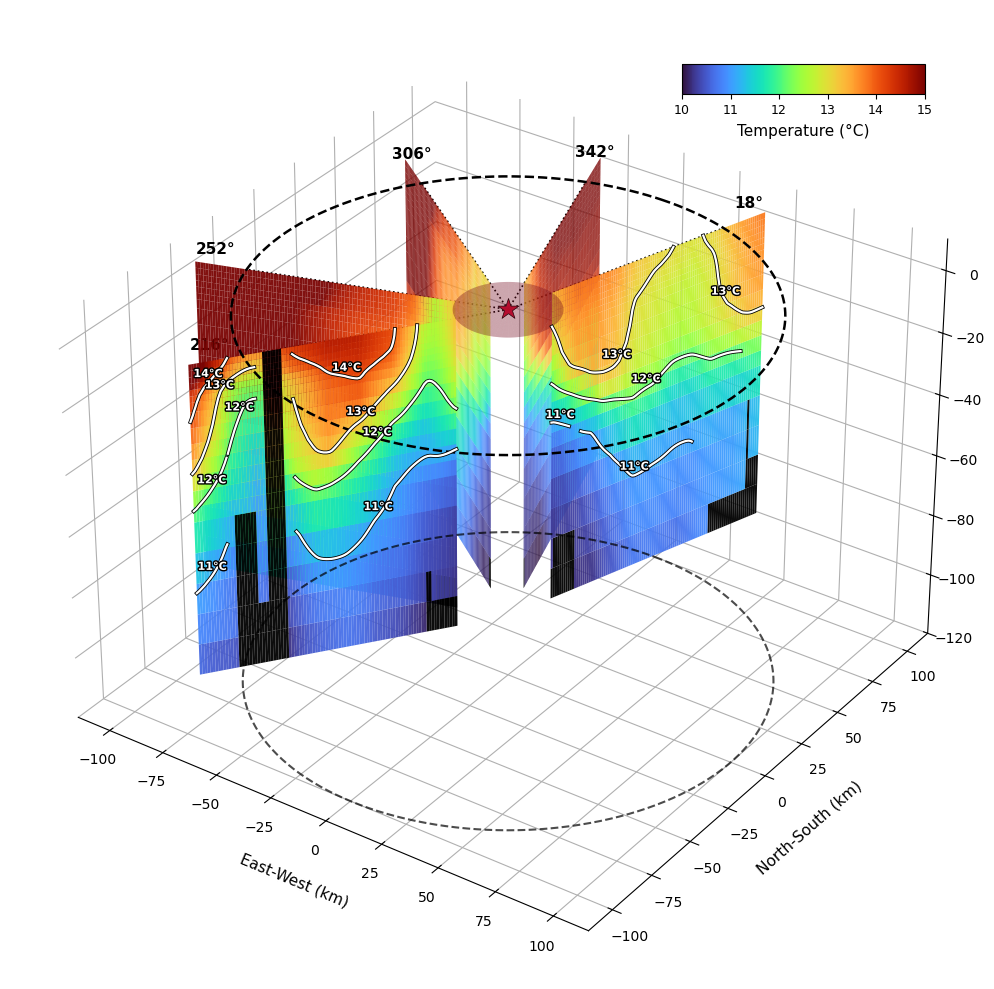

In [109]:
# ============================================================
# DATASETS
# ============================================================
angles = [18, 342, 306, 252, 216]

sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]

# Angles where thermoclines should be drawn
target_angles = [18, 216]

# ============================================================
# HELPER FUNCTION FOR CONTOUR EXTRACTION
# ============================================================
def extract_contour_segments(cs):
    segments = []
    
    # Matplotlib >= 3.8
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    # Matplotlib < 3.8
    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments

    return segments

# ============================================================
# FIGURE & AXES SETUP
# ============================================================
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

cmap = plt.cm.turbo  
norm = Normalize(vmin=10, vmax=15)

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)

# Clean up pane backgrounds
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor('w')
ax.yaxis.pane.set_edgecolor('w')
ax.zaxis.pane.set_edgecolor('w')

# Key thermocline levels (°C)
contour_levels = [11.0, 12.0, 13.0, 14.0]

# Temporary 2D figure to compute contour paths
fig_temp, ax_temp = plt.subplots()

# ============================================================
# Plot sections
# ============================================================
for ang, ds in zip(angles, sections):
    theta = np.deg2rad(ang)

    distance = ds['distance'].values + station_radius
    depth = ds['depth'][:20].values
    temp = ds['temp'][5, :20, :].values  # Shape: (depth_len, distance_len)

    D, Z = np.meshgrid(distance, depth)

    # Geographic coordinates
    X = D * np.sin(theta)
    Y = D * np.cos(theta)
    Z_mesh = -Z

    colors = cmap(norm(temp))
    colors[..., 3] = 0.95  # Light transparency

    # 1. Main surface section panel
    ax.plot_surface(
        X, Y, Z_mesh,
        facecolors=colors,
        rstride=1, cstride=1,
        linewidth=0,
        antialiased=True,
        shade=False
    )

    # 2. Add Thermoclines ONLY for 18° and 216° sections
    if ang in target_angles:
        # Smooth temperature field slightly to remove grid artifacts
        temp_smooth = gaussian_filter(temp, sigma=0.8)

        cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
        contour_segments = extract_contour_segments(cs)

        for level_val, verts in contour_segments:
            if len(verts) < 10:  # Ignore short noise segments
                continue

            d_pts = verts[:, 0]
            z_pts = verts[:, 1]

            # Convert 2D (Distance, Depth) -> 3D (X, Y, Z)
            x_pts = d_pts * np.sin(theta)
            y_pts = d_pts * np.cos(theta)

            # Draw smooth thermocline contour line
            line, = ax.plot(
                x_pts, y_pts, z_pts,
                color='white',
                lw=1.6,
                ls='-',
                zorder=30
            )
            line.set_path_effects([
                path_effects.Stroke(linewidth=2.8, foreground='black'),
                path_effects.Normal()
            ])

            # Label near the middle of each thermocline line
            mid_idx = len(x_pts) // 2
            ax.text(
                x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                f'{level_val:.0f}°C',
                color='white',
                fontsize=8,
                fontweight='bold',
                ha='center',
                va='bottom',
                zorder=35,
                path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
            )

# Close hidden helper figure
plt.close(fig_temp)

# ============================================================
# Draw Circumferences (Surface Z=0 & Bottom Z=-120)
# ============================================================
t = np.linspace(0, 2 * np.pi, 500)

# Bottom circumference around the base
ax.plot(
    R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t),
    '--k', lw=1.5, alpha=0.7, zorder=10
)

# Surface circumference
ax.plot(
    R * np.sin(t), R * np.cos(t), np.zeros_like(t),
    '--k', lw=1.8, zorder=10
)

# ============================================================
# Draw radial lines and labels
# ============================================================
for ang in angles:
    theta = np.deg2rad(ang)

    ax.plot(
        [0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0],
        color='k', lw=1.2, ls=':'
    )

    ax.text(
        112 * np.sin(theta),
        112 * np.cos(theta),
        5,
        f'{ang}°',
        fontsize=11,
        fontweight='bold',
        ha='center',
        va='center'
    )

# ============================================================
# Center Station Indicator
# ============================================================
r = np.linspace(0, station_radius, 50)
th = np.linspace(0, 2 * np.pi, 200)
RR, TT = np.meshgrid(r, th)

XX = RR * np.sin(TT)
YY = RR * np.cos(TT)
ZZ = np.zeros_like(XX)

ax.plot_surface(
    XX, YY, ZZ,
    color='crimson',
    alpha=0.4,
    linewidth=0
)

ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

# ============================================================
# Limits and Labels
# ============================================================
ax.set_xlim(-115, 115)
ax.set_ylim(-115, 115)
ax.set_zlim(-max_depth, 10)

ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)

ax.set_box_aspect((1, 1, 0.75))
ax.view_init(elev=32, azim=305)

# ============================================================
# INSET COLORBAR (Inside figure canvas)
# ============================================================
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax,
    width="25%",      # Width of the colorbar relative to axes
    height="3%",      # Height relative to axes
    loc='upper right',
    bbox_to_anchor=(-0.05, -0.05, 1, 1),
    bbox_transform=ax.transAxes
)

cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
cb.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

/tmp/ipykernel_22334/2267698643.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


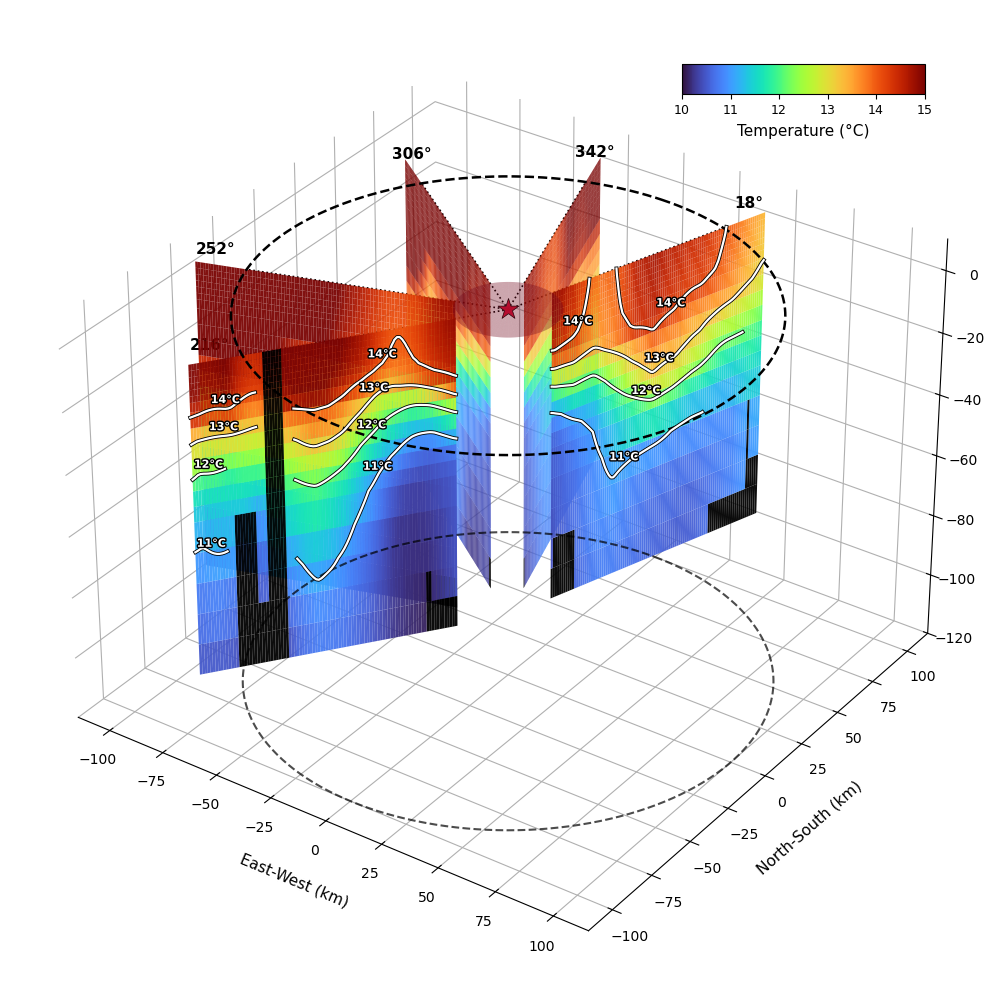

In [110]:
# ============================================================
# DATASETS
# ============================================================
angles = [18, 342, 306, 252, 216]

sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]

# Angles where thermoclines should be drawn
target_angles = [18, 216]

# ============================================================
# HELPER FUNCTION FOR CONTOUR EXTRACTION
# ============================================================
def extract_contour_segments(cs):
    segments = []
    
    # Matplotlib >= 3.8
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    # Matplotlib < 3.8
    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments

    return segments

# ============================================================
# FIGURE & AXES SETUP
# ============================================================
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

cmap = plt.cm.turbo  
norm = Normalize(vmin=10, vmax=15)

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)

# Clean up pane backgrounds
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor('w')
ax.yaxis.pane.set_edgecolor('w')
ax.zaxis.pane.set_edgecolor('w')

# Key thermocline levels (°C)
contour_levels = [11.0, 12.0, 13.0, 14.0]

# Temporary 2D figure to compute contour paths
fig_temp, ax_temp = plt.subplots()

# ============================================================
# Plot sections
# ============================================================
for ang, ds in zip(angles, sections):
    theta = np.deg2rad(ang)

    distance = ds['distance'].values + station_radius
    depth = ds['depth'][:20].values
    temp = ds['temp'][10, :20, :].values  # Shape: (depth_len, distance_len)

    D, Z = np.meshgrid(distance, depth)

    # Geographic coordinates
    X = D * np.sin(theta)
    Y = D * np.cos(theta)
    Z_mesh = -Z

    colors = cmap(norm(temp))
    colors[..., 3] = 0.95  # Light transparency

    # 1. Main surface section panel
    ax.plot_surface(
        X, Y, Z_mesh,
        facecolors=colors,
        rstride=1, cstride=1,
        linewidth=0,
        antialiased=True,
        shade=False
    )

    # 2. Add Thermoclines ONLY for 18° and 216° sections
    if ang in target_angles:
        # Smooth temperature field slightly to remove grid artifacts
        temp_smooth = gaussian_filter(temp, sigma=0.8)

        cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
        contour_segments = extract_contour_segments(cs)

        for level_val, verts in contour_segments:
            if len(verts) < 10:  # Ignore short noise segments
                continue

            d_pts = verts[:, 0]
            z_pts = verts[:, 1]

            # Convert 2D (Distance, Depth) -> 3D (X, Y, Z)
            x_pts = d_pts * np.sin(theta)
            y_pts = d_pts * np.cos(theta)

            # Draw smooth thermocline contour line
            line, = ax.plot(
                x_pts, y_pts, z_pts,
                color='white',
                lw=1.6,
                ls='-',
                zorder=30
            )
            line.set_path_effects([
                path_effects.Stroke(linewidth=2.8, foreground='black'),
                path_effects.Normal()
            ])

            # Label near the middle of each thermocline line
            mid_idx = len(x_pts) // 2
            ax.text(
                x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                f'{level_val:.0f}°C',
                color='white',
                fontsize=8,
                fontweight='bold',
                ha='center',
                va='bottom',
                zorder=35,
                path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
            )

# Close hidden helper figure
plt.close(fig_temp)

# ============================================================
# Draw Circumferences (Surface Z=0 & Bottom Z=-120)
# ============================================================
t = np.linspace(0, 2 * np.pi, 500)

# Bottom circumference around the base
ax.plot(
    R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t),
    '--k', lw=1.5, alpha=0.7, zorder=10
)

# Surface circumference
ax.plot(
    R * np.sin(t), R * np.cos(t), np.zeros_like(t),
    '--k', lw=1.8, zorder=10
)

# ============================================================
# Draw radial lines and labels
# ============================================================
for ang in angles:
    theta = np.deg2rad(ang)

    ax.plot(
        [0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0],
        color='k', lw=1.2, ls=':'
    )

    ax.text(
        112 * np.sin(theta),
        112 * np.cos(theta),
        5,
        f'{ang}°',
        fontsize=11,
        fontweight='bold',
        ha='center',
        va='center'
    )

# ============================================================
# Center Station Indicator
# ============================================================
r = np.linspace(0, station_radius, 50)
th = np.linspace(0, 2 * np.pi, 200)
RR, TT = np.meshgrid(r, th)

XX = RR * np.sin(TT)
YY = RR * np.cos(TT)
ZZ = np.zeros_like(XX)

ax.plot_surface(
    XX, YY, ZZ,
    color='crimson',
    alpha=0.4,
    linewidth=0
)

ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

# ============================================================
# Limits and Labels
# ============================================================
ax.set_xlim(-115, 115)
ax.set_ylim(-115, 115)
ax.set_zlim(-max_depth, 10)

ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)

ax.set_box_aspect((1, 1, 0.75))
ax.view_init(elev=32, azim=305)

# ============================================================
# INSET COLORBAR (Inside figure canvas)
# ============================================================
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax,
    width="25%",      # Width of the colorbar relative to axes
    height="3%",      # Height relative to axes
    loc='upper right',
    bbox_to_anchor=(-0.05, -0.05, 1, 1),
    bbox_transform=ax.transAxes
)

cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
cb.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

/tmp/ipykernel_22334/2962892192.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


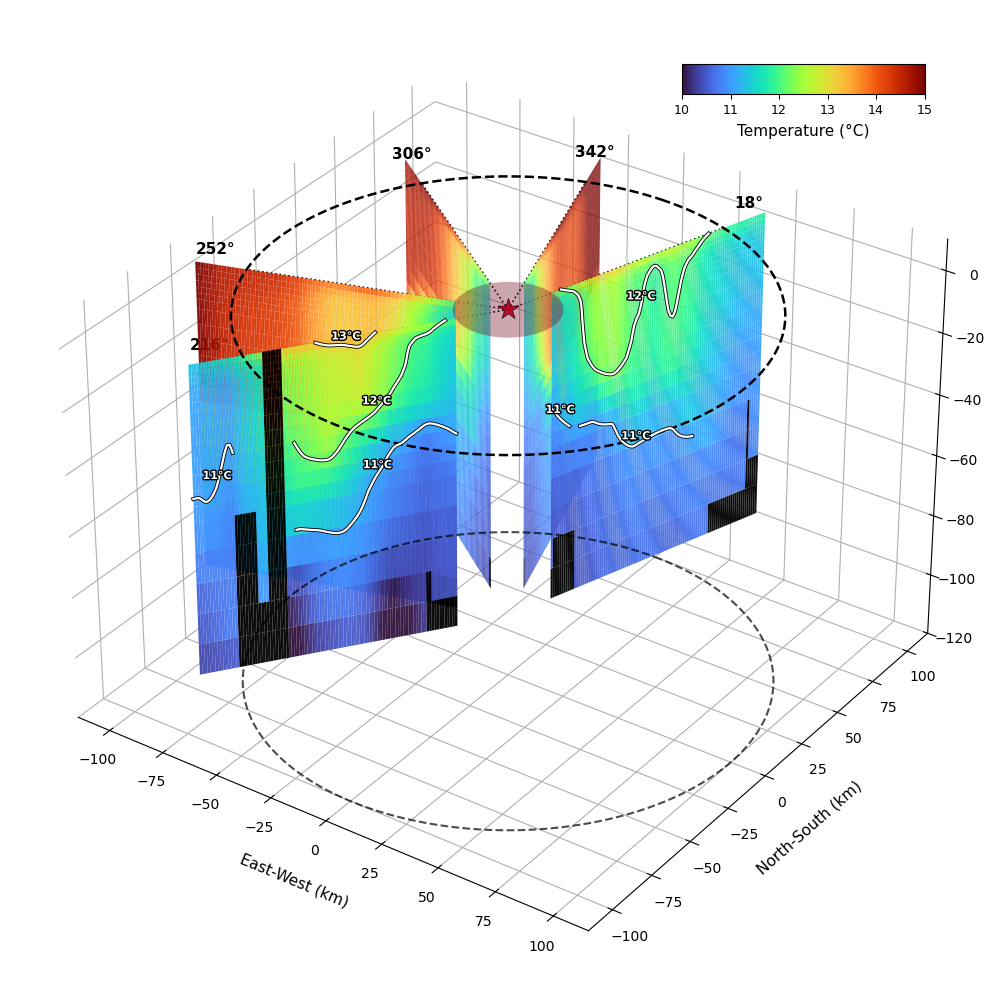

In [111]:
# ============================================================
# DATASETS
# ============================================================
angles = [18, 342, 306, 252, 216]

sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]

# Angles where thermoclines should be drawn
target_angles = [18, 216]

# ============================================================
# HELPER FUNCTION FOR CONTOUR EXTRACTION
# ============================================================
def extract_contour_segments(cs):
    segments = []
    
    # Matplotlib >= 3.8
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    # Matplotlib < 3.8
    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments

    return segments

# ============================================================
# FIGURE & AXES SETUP
# ============================================================
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

cmap = plt.cm.turbo  
norm = Normalize(vmin=10, vmax=15)

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)

# Clean up pane backgrounds
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor('w')
ax.yaxis.pane.set_edgecolor('w')
ax.zaxis.pane.set_edgecolor('w')

# Key thermocline levels (°C)
contour_levels = [11.0, 12.0, 13.0, 14.0]

# Temporary 2D figure to compute contour paths
fig_temp, ax_temp = plt.subplots()

# ============================================================
# Plot sections
# ============================================================
for ang, ds in zip(angles, sections):
    theta = np.deg2rad(ang)

    distance = ds['distance'].values + station_radius
    depth = ds['depth'][:20].values
    temp = ds['temp'][16, :20, :].values  # Shape: (depth_len, distance_len)

    D, Z = np.meshgrid(distance, depth)

    # Geographic coordinates
    X = D * np.sin(theta)
    Y = D * np.cos(theta)
    Z_mesh = -Z

    colors = cmap(norm(temp))
    colors[..., 3] = 0.95  # Light transparency

    # 1. Main surface section panel
    ax.plot_surface(
        X, Y, Z_mesh,
        facecolors=colors,
        rstride=1, cstride=1,
        linewidth=0,
        antialiased=True,
        shade=False
    )

    # 2. Add Thermoclines ONLY for 18° and 216° sections
    if ang in target_angles:
        # Smooth temperature field slightly to remove grid artifacts
        temp_smooth = gaussian_filter(temp, sigma=0.8)

        cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
        contour_segments = extract_contour_segments(cs)

        for level_val, verts in contour_segments:
            if len(verts) < 10:  # Ignore short noise segments
                continue

            d_pts = verts[:, 0]
            z_pts = verts[:, 1]

            # Convert 2D (Distance, Depth) -> 3D (X, Y, Z)
            x_pts = d_pts * np.sin(theta)
            y_pts = d_pts * np.cos(theta)

            # Draw smooth thermocline contour line
            line, = ax.plot(
                x_pts, y_pts, z_pts,
                color='white',
                lw=1.6,
                ls='-',
                zorder=30
            )
            line.set_path_effects([
                path_effects.Stroke(linewidth=2.8, foreground='black'),
                path_effects.Normal()
            ])

            # Label near the middle of each thermocline line
            mid_idx = len(x_pts) // 2
            ax.text(
                x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                f'{level_val:.0f}°C',
                color='white',
                fontsize=8,
                fontweight='bold',
                ha='center',
                va='bottom',
                zorder=35,
                path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
            )

# Close hidden helper figure
plt.close(fig_temp)

# ============================================================
# Draw Circumferences (Surface Z=0 & Bottom Z=-120)
# ============================================================
t = np.linspace(0, 2 * np.pi, 500)

# Bottom circumference around the base
ax.plot(
    R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t),
    '--k', lw=1.5, alpha=0.7, zorder=10
)

# Surface circumference
ax.plot(
    R * np.sin(t), R * np.cos(t), np.zeros_like(t),
    '--k', lw=1.8, zorder=10
)

# ============================================================
# Draw radial lines and labels
# ============================================================
for ang in angles:
    theta = np.deg2rad(ang)

    ax.plot(
        [0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0],
        color='k', lw=1.2, ls=':'
    )

    ax.text(
        112 * np.sin(theta),
        112 * np.cos(theta),
        5,
        f'{ang}°',
        fontsize=11,
        fontweight='bold',
        ha='center',
        va='center'
    )

# ============================================================
# Center Station Indicator
# ============================================================
r = np.linspace(0, station_radius, 50)
th = np.linspace(0, 2 * np.pi, 200)
RR, TT = np.meshgrid(r, th)

XX = RR * np.sin(TT)
YY = RR * np.cos(TT)
ZZ = np.zeros_like(XX)

ax.plot_surface(
    XX, YY, ZZ,
    color='crimson',
    alpha=0.4,
    linewidth=0
)

ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

# ============================================================
# Limits and Labels
# ============================================================
ax.set_xlim(-115, 115)
ax.set_ylim(-115, 115)
ax.set_zlim(-max_depth, 10)

ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)

ax.set_box_aspect((1, 1, 0.75))
ax.view_init(elev=32, azim=305)

# ============================================================
# INSET COLORBAR (Inside figure canvas)
# ============================================================
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax,
    width="25%",      # Width of the colorbar relative to axes
    height="3%",      # Height relative to axes
    loc='upper right',
    bbox_to_anchor=(-0.05, -0.05, 1, 1),
    bbox_transform=ax.transAxes
)

cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
cb.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

In [112]:
# Video

In [113]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.patheffects as path_effects
from scipy.ndimage import gaussian_filter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.cm as cm
from matplotlib.animation import FuncAnimation, FFMpegWriter

# ============================================================
# DATASETS & SETUP
# ============================================================
angles = [18, 342, 306, 252, 216]
sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]
target_angles = [18, 216]

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)
contour_levels = [11.0, 12.0, 13.0, 14.0]

cmap = plt.cm.turbo  
norm = Normalize(vmin=10, vmax=15)

# ============================================================
# HELPER FUNCTIONS
# ============================================================
def extract_contour_segments(cs):
    segments = []
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments
    return segments

# ============================================================
# ANIMATION UPDATE FUNCTION
# ============================================================
fig = plt.figure(figsize=(12, 10))

def update(frame_idx):
    fig.clear()
    
    ax = fig.add_subplot(111, projection='3d')

    # Clean up pane backgrounds
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('w')
    ax.yaxis.pane.set_edgecolor('w')
    ax.zaxis.pane.set_edgecolor('w')

    fig_temp, ax_temp = plt.subplots()

    # Plot each cross-section for the given frame_idx (0 to 30)
    for ang, ds in zip(angles, sections):
        theta = np.deg2rad(ang)

        distance = ds['distance'].values + station_radius
        depth = ds['depth'][:20].values
        
        # Dynamically sample temperature at current index: frame_idx
        temp = ds['temp'][frame_idx, :20, :].values  

        D, Z = np.meshgrid(distance, depth)

        # Geographic coordinates
        X = D * np.sin(theta)
        Y = D * np.cos(theta)
        Z_mesh = -Z

        colors = cmap(norm(temp))
        colors[..., 3] = 0.95  # Transparency

        # 1. Main surface section panel
        ax.plot_surface(
            X, Y, Z_mesh,
            facecolors=colors,
            rstride=1, cstride=1,
            linewidth=0,
            antialiased=True,
            shade=False
        )

        # 2. Add Thermoclines ONLY for target angles
        if ang in target_angles:
            temp_smooth = gaussian_filter(temp, sigma=0.8)
            cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
            contour_segments = extract_contour_segments(cs)

            for level_val, verts in contour_segments:
                if len(verts) < 10:
                    continue

                d_pts = verts[:, 0]
                z_pts = verts[:, 1]

                x_pts = d_pts * np.sin(theta)
                y_pts = d_pts * np.cos(theta)

                line, = ax.plot(
                    x_pts, y_pts, z_pts,
                    color='white', lw=1.6, ls='-', zorder=30
                )
                line.set_path_effects([
                    path_effects.Stroke(linewidth=2.8, foreground='black'),
                    path_effects.Normal()
                ])

                mid_idx = len(x_pts) // 2
                ax.text(
                    x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                    f'{level_val:.0f}°C',
                    color='white', fontsize=8, fontweight='bold',
                    ha='center', va='bottom', zorder=35,
                    path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
                )

    plt.close(fig_temp)

    # Circumferences (Surface & Bottom)
    t = np.linspace(0, 2 * np.pi, 500)
    ax.plot(R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t), '--k', lw=1.5, alpha=0.7, zorder=10)
    ax.plot(R * np.sin(t), R * np.cos(t), np.zeros_like(t), '--k', lw=1.8, zorder=10)

    # Radial lines and angle labels
    for ang in angles:
        theta = np.deg2rad(ang)
        ax.plot([0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0], color='k', lw=1.2, ls=':')
        ax.text(112 * np.sin(theta), 112 * np.cos(theta), 5, f'{ang}°', fontsize=11, fontweight='bold', ha='center', va='center')

    # Center station indicator
    r = np.linspace(0, station_radius, 50)
    th = np.linspace(0, 2 * np.pi, 200)
    RR, TT = np.meshgrid(r, th)
    XX, YY = RR * np.sin(TT), RR * np.cos(TT)
    ZZ = np.zeros_like(XX)

    ax.plot_surface(XX, YY, ZZ, color='crimson', alpha=0.4, linewidth=0)
    ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

    # Axes limits, labels, title
    ax.set_xlim(-115, 115)
    ax.set_ylim(-115, 115)
    ax.set_zlim(-max_depth, 10)
    ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
    ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
    ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)
    ax.set_title(f'Temperature Index: {frame_idx}', fontsize=14, pad=15)

    ax.set_box_aspect((1, 1, 0.75))
    ax.view_init(elev=32, azim=305)

    # Inset Colorbar
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cax = inset_axes(
        ax, width="25%", height="3%", loc='upper right',
        bbox_to_anchor=(-0.05, -0.05, 1, 1), bbox_transform=ax.transAxes
    )
    cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
    cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
    cb.ax.tick_params(labelsize=9)

# ============================================================
# CREATE & SAVE VIDEO
# ============================================================
# Frames run from 0 to 30 inclusive (31 total frames)
anim = FuncAnimation(fig, update, frames=range(31), interval=200)

# Option A: Save as MP4 (Requires ffmpeg installed on your system)
writer = FFMpegWriter(fps=5, metadata=dict(artist='Oceanography'), bitrate=1800)
anim.save('T01.mp4', writer=writer)

# Option B: Save as GIF (If ffmpeg is not installed)
# anim.save('temperature_section_evolution.gif', writer='pillow', fps=5)

plt.close()

In [114]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.patheffects as path_effects
from scipy.ndimage import gaussian_filter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.cm as cm
# Switched from FFMpegWriter to PillowWriter for GIF generation
from matplotlib.animation import FuncAnimation, PillowWriter

# ============================================================
# DATASETS & SETUP
# ============================================================
angles = [18, 342, 306, 252, 216]
sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]
target_angles = [18, 216]

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)
contour_levels = [11.0, 12.0, 13.0, 14.0]

cmap = plt.cm.turbo  
norm = Normalize(vmin=10, vmax=15)

# ============================================================
# HELPER FUNCTIONS
# ============================================================
def extract_contour_segments(cs):
    segments = []
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments
    return segments

# ============================================================
# ANIMATION UPDATE FUNCTION
# ============================================================
fig = plt.figure(figsize=(12, 10))

def update(frame_idx):
    fig.clear()
    
    ax = fig.add_subplot(111, projection='3d')

    # Clean up pane backgrounds
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('w')
    ax.yaxis.pane.set_edgecolor('w')
    ax.zaxis.pane.set_edgecolor('w')

    fig_temp, ax_temp = plt.subplots()

    # Plot each cross-section for the given frame_idx (0 to 30)
    for ang, ds in zip(angles, sections):
        theta = np.deg2rad(ang)

        distance = ds['distance'].values + station_radius
        depth = ds['depth'][:20].values
        
        # Dynamically sample temperature at current index: frame_idx
        temp = ds['temp'][frame_idx, :20, :].values  

        D, Z = np.meshgrid(distance, depth)

        # Geographic coordinates
        X = D * np.sin(theta)
        Y = D * np.cos(theta)
        Z_mesh = -Z

        colors = cmap(norm(temp))
        colors[..., 3] = 0.95  # Transparency

        # 1. Main surface section panel
        ax.plot_surface(
            X, Y, Z_mesh,
            facecolors=colors,
            rstride=1, cstride=1,
            linewidth=0,
            antialiased=True,
            shade=False
        )

        # 2. Add Thermoclines ONLY for target angles
        if ang in target_angles:
            temp_smooth = gaussian_filter(temp, sigma=0.8)
            cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
            contour_segments = extract_contour_segments(cs)

            for level_val, verts in contour_segments:
                if len(verts) < 10:
                    continue

                d_pts = verts[:, 0]
                z_pts = verts[:, 1]

                x_pts = d_pts * np.sin(theta)
                y_pts = d_pts * np.cos(theta)

                line, = ax.plot(
                    x_pts, y_pts, z_pts,
                    color='white', lw=1.6, ls='-', zorder=30
                )
                line.set_path_effects([
                    path_effects.Stroke(linewidth=2.8, foreground='black'),
                    path_effects.Normal()
                ])

                mid_idx = len(x_pts) // 2
                ax.text(
                    x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                    f'{level_val:.0f}°C',
                    color='white', fontsize=8, fontweight='bold',
                    ha='center', va='bottom', zorder=35,
                    path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
                )

    plt.close(fig_temp)

    # Circumferences (Surface & Bottom)
    t = np.linspace(0, 2 * np.pi, 500)
    ax.plot(R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t), '--k', lw=1.5, alpha=0.7, zorder=10)
    ax.plot(R * np.sin(t), R * np.cos(t), np.zeros_like(t), '--k', lw=1.8, zorder=10)

    # Radial lines and angle labels
    for ang in angles:
        theta = np.deg2rad(ang)
        ax.plot([0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0], color='k', lw=1.2, ls=':')
        ax.text(112 * np.sin(theta), 112 * np.cos(theta), 5, f'{ang}°', fontsize=11, fontweight='bold', ha='center', va='center')

    # Center station indicator
    r = np.linspace(0, station_radius, 50)
    th = np.linspace(0, 2 * np.pi, 200)
    RR, TT = np.meshgrid(r, th)
    XX, YY = RR * np.sin(TT), RR * np.cos(TT)
    ZZ = np.zeros_like(XX)

    ax.plot_surface(XX, YY, ZZ, color='crimson', alpha=0.4, linewidth=0)
    ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

    # Axes limits, labels, title
    ax.set_xlim(-115, 115)
    ax.set_ylim(-115, 115)
    ax.set_zlim(-max_depth, 10)
    ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
    ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
    ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)
    ax.set_title(f'Temperature Index: {frame_idx}', fontsize=14, pad=15)

    ax.set_box_aspect((1, 1, 0.75))
    ax.view_init(elev=32, azim=305)

    # Inset Colorbar
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cax = inset_axes(
        ax, width="25%", height="3%", loc='upper right',
        bbox_to_anchor=(-0.05, -0.05, 1, 1), bbox_transform=ax.transAxes
    )
    cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
    cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
    cb.ax.tick_params(labelsize=9)

# ============================================================
# CREATE & SAVE VIDEO AS A GIF
# ============================================================
# Frames run from 0 to 30 inclusive (31 total frames)
anim = FuncAnimation(fig, update, frames=range(31), interval=200)

# Save as GIF using PillowWriter (does not require external system installations like ffmpeg)
writer = PillowWriter(fps=5)
anim.save('T01.gif', writer=writer)

plt.close()

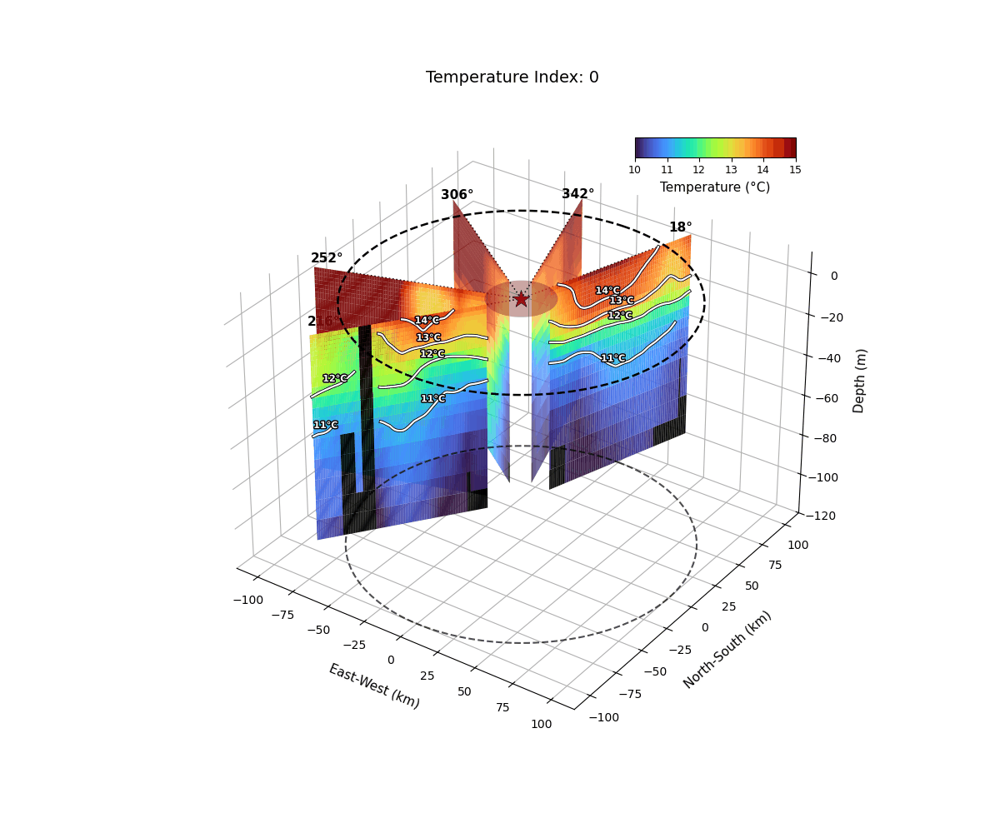

In [115]:
from IPython.display import Image, display

# Display the local GIF file in the notebook output
display(Image(filename='T01.gif'))

In [116]:
pwd

'/home/cl/Google/@doctorado-sync/database/hycom-sim'

In [117]:
#

In [118]:
# 1. Load the specific angle Dataset from the saved NetCDF file
file_path = "./radial_sections/section_angle_018deg_07.nc"
dsX01_1 = xr.open_dataset(file_path)
dsX01_1_mean = dsX01_1.mean(dim="time")
dsX01_1_daily = dsX01_1.resample(time='1D').mean()

file_path = "./radial_sections/section_angle_342deg_07.nc"
dsX01_2 = xr.open_dataset(file_path)
dsX01_2_mean = dsX01_2.mean(dim="time")
dsX01_2_daily = dsX01_2.resample(time='1D').mean()

file_path = "./radial_sections/section_angle_306deg_07.nc"
dsX01_3 = xr.open_dataset(file_path)
dsX01_3_mean = dsX01_3.mean(dim="time")
dsX01_3_daily = dsX01_3.resample(time='1D').mean()

file_path = "./radial_sections/section_angle_252deg_07.nc"
dsX01_4 = xr.open_dataset(file_path)
dsX01_4_mean = dsX01_4.mean(dim="time")
dsX01_4_daily = dsX01_4.resample(time='1D').mean()

file_path = "./radial_sections/section_angle_216deg_07.nc"
dsX01_5 = xr.open_dataset(file_path)
dsX01_5_mean = dsX01_5.mean(dim="time")
dsX01_5_daily = dsX01_5.resample(time='1D').mean()

In [119]:
#

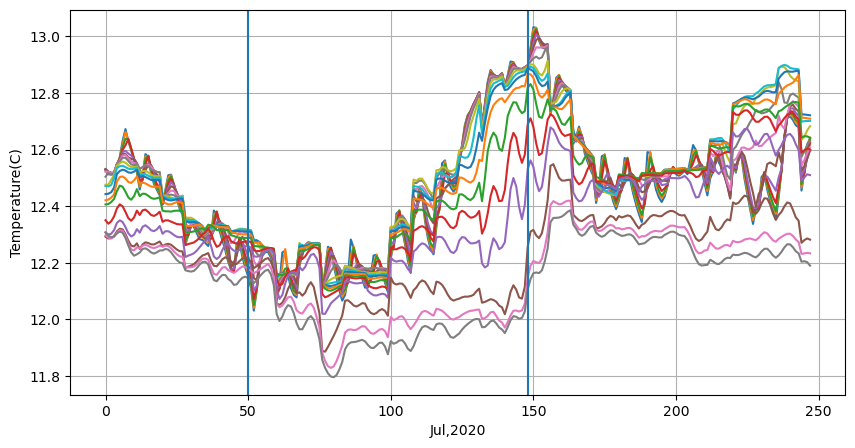

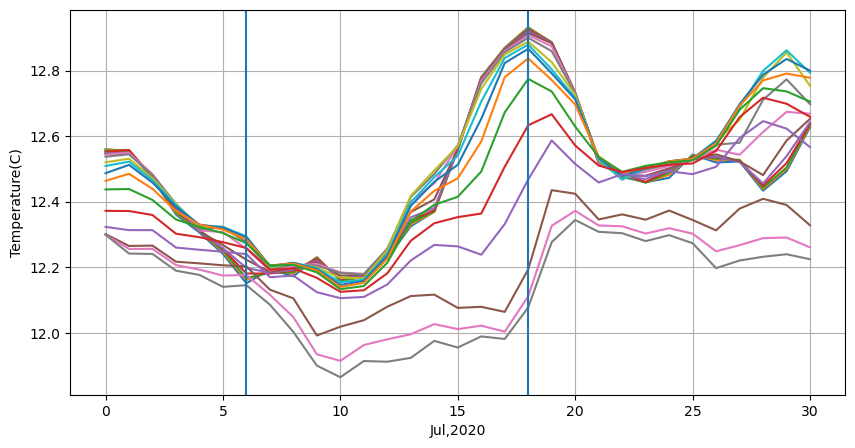

In [120]:
plt.figure(figsize=(10,5))
for i in range(0,20):
    plt.plot(dsX01_1['temp'][:,i,0])
plt.ylabel('Temperature(C)')
plt.xlabel('Jul,2020')
plt.axvline(50)
plt.axvline(148)
plt.grid()

#---------------------------------
#---------------------------------

plt.figure(figsize=(10,5))
for i in range(0,20):
    plt.plot(dsX01_1_daily['temp'][:,i,0])
plt.ylabel('Temperature(C)')
plt.xlabel('Jul,2020')
plt.axvline(6)
plt.axvline(18)
plt.grid()

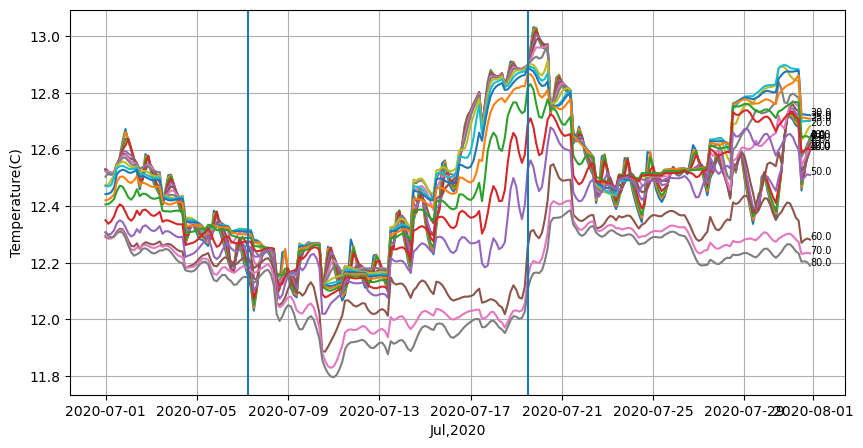

In [121]:
plt.figure(figsize=(10,5))
for i in range(0,20):
    plt.plot(dsX01_1['time'],dsX01_1['temp'][:,i,0])
    plt.text(dsX01_1['time'][-1],dsX01_1['temp'][-1,i,0], dsX01_1['depth'][i].values, fontsize = 7)
plt.ylabel('Temperature(C)')
plt.xlabel('Jul,2020')
plt.grid()
plt.axvline(dsX01_1['time'][50].values)
plt.axvline(dsX01_1['time'][148].values)

In [122]:
ds['temp'][30, :20, :].values

array([[13.98865234, 13.94921871, 13.9089653 , ..., 12.09161598,
        12.10085534, 12.11274704],
       [13.96531189, 13.92593965, 13.88572852, ..., 12.06605773,
        12.07495632, 12.08651299],
       [13.93573094, 13.89652261, 13.85647538, ..., 12.03831108,
        12.04705254, 12.05842911],
       ...,
       [11.15701672, 11.14593511, 11.13474076, ..., 11.08659481,
        11.08953502, 11.09224957],
       [        nan,         nan,         nan, ..., 10.93855946,
        10.94736456, 10.95497639],
       [        nan,         nan,         nan, ..., 10.80224854,
        10.81101484, 10.81973524]], shape=(20, 100))

/tmp/ipykernel_22334/2172171111.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


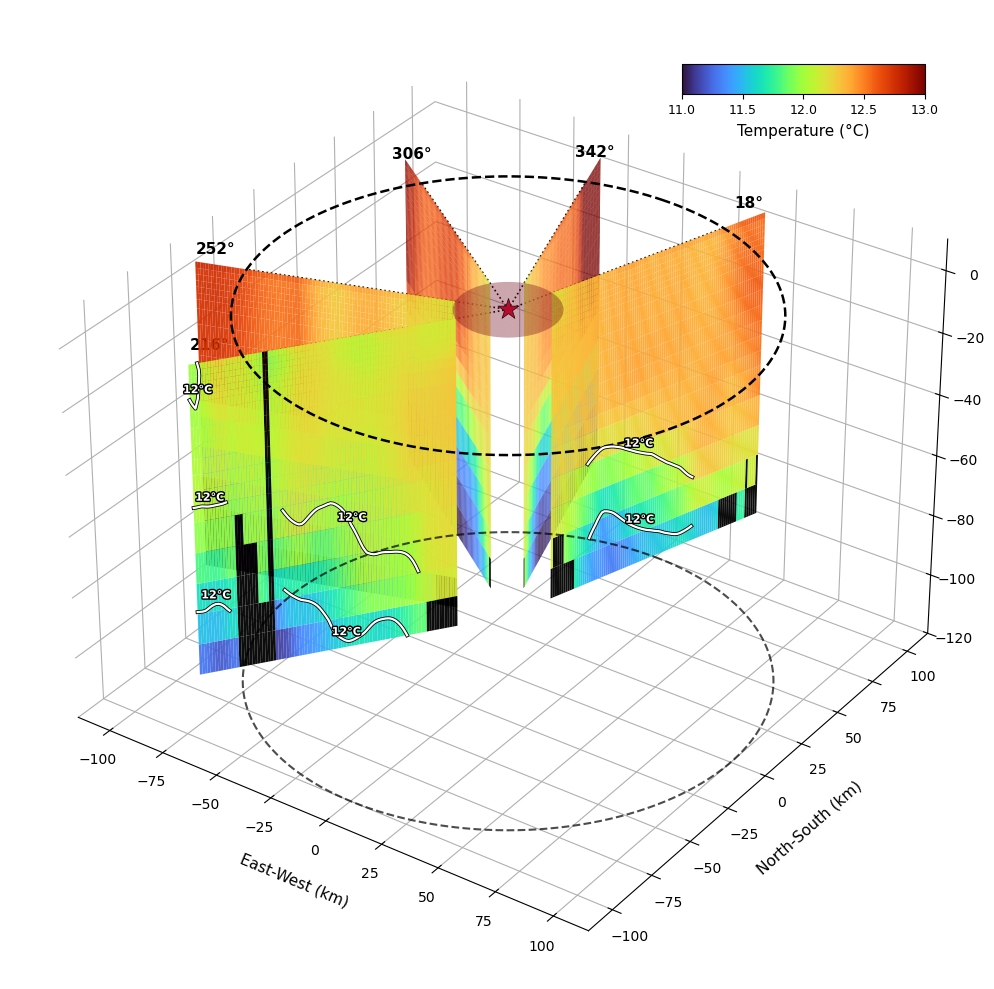

In [123]:
# ============================================================
# DATASETS
# ============================================================
angles = [18, 342, 306, 252, 216]

sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]

# Angles where thermoclines should be drawn
target_angles = [18, 216]

# ============================================================
# HELPER FUNCTION FOR CONTOUR EXTRACTION
# ============================================================
def extract_contour_segments(cs):
    segments = []
    
    # Matplotlib >= 3.8
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    # Matplotlib < 3.8
    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments

    return segments

# ============================================================
# FIGURE & AXES SETUP
# ============================================================
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

cmap = plt.cm.turbo  
norm = Normalize(vmin=11, vmax=13)

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)

# Clean up pane backgrounds
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor('w')
ax.yaxis.pane.set_edgecolor('w')
ax.zaxis.pane.set_edgecolor('w')

# Key thermocline levels (°C)
contour_levels = [11.5, 12]

# Temporary 2D figure to compute contour paths
fig_temp, ax_temp = plt.subplots()

# ============================================================
# Plot sections
# ============================================================
for ang, ds in zip(angles, sections):
    theta = np.deg2rad(ang)

    distance = ds['distance'].values + station_radius
    depth = ds['depth'][:20].values
    temp = ds['temp'][6, :20, :].values  # Shape: (depth_len, distance_len)

    D, Z = np.meshgrid(distance, depth)

    # Geographic coordinates
    X = D * np.sin(theta)
    Y = D * np.cos(theta)
    Z_mesh = -Z

    colors = cmap(norm(temp))
    colors[..., 3] = 0.95  # Light transparency

    # 1. Main surface section panel
    ax.plot_surface(
        X, Y, Z_mesh,
        facecolors=colors,
        rstride=1, cstride=1,
        linewidth=0,
        antialiased=True,
        shade=False
    )

    # 2. Add Thermoclines ONLY for 18° and 216° sections
    if ang in target_angles:
        # Smooth temperature field slightly to remove grid artifacts
        temp_smooth = gaussian_filter(temp, sigma=0.8)

        cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
        contour_segments = extract_contour_segments(cs)

        for level_val, verts in contour_segments:
            if len(verts) < 10:  # Ignore short noise segments
                continue

            d_pts = verts[:, 0]
            z_pts = verts[:, 1]

            # Convert 2D (Distance, Depth) -> 3D (X, Y, Z)
            x_pts = d_pts * np.sin(theta)
            y_pts = d_pts * np.cos(theta)

            # Draw smooth thermocline contour line
            line, = ax.plot(
                x_pts, y_pts, z_pts,
                color='white',
                lw=1.6,
                ls='-',
                zorder=30
            )
            line.set_path_effects([
                path_effects.Stroke(linewidth=2.8, foreground='black'),
                path_effects.Normal()
            ])

            # Label near the middle of each thermocline line
            mid_idx = len(x_pts) // 2
            ax.text(
                x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                f'{level_val:.0f}°C',
                color='white',
                fontsize=8,
                fontweight='bold',
                ha='center',
                va='bottom',
                zorder=35,
                path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
            )

# Close hidden helper figure
plt.close(fig_temp)

# ============================================================
# Draw Circumferences (Surface Z=0 & Bottom Z=-120)
# ============================================================
t = np.linspace(0, 2 * np.pi, 500)

# Bottom circumference around the base
ax.plot(
    R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t),
    '--k', lw=1.5, alpha=0.7, zorder=10
)

# Surface circumference
ax.plot(
    R * np.sin(t), R * np.cos(t), np.zeros_like(t),
    '--k', lw=1.8, zorder=10
)

# ============================================================
# Draw radial lines and labels
# ============================================================
for ang in angles:
    theta = np.deg2rad(ang)

    ax.plot(
        [0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0],
        color='k', lw=1.2, ls=':'
    )

    ax.text(
        112 * np.sin(theta),
        112 * np.cos(theta),
        5,
        f'{ang}°',
        fontsize=11,
        fontweight='bold',
        ha='center',
        va='center'
    )

# ============================================================
# Center Station Indicator
# ============================================================
r = np.linspace(0, station_radius, 50)
th = np.linspace(0, 2 * np.pi, 200)
RR, TT = np.meshgrid(r, th)

XX = RR * np.sin(TT)
YY = RR * np.cos(TT)
ZZ = np.zeros_like(XX)

ax.plot_surface(
    XX, YY, ZZ,
    color='crimson',
    alpha=0.4,
    linewidth=0
)

ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

# ============================================================
# Limits and Labels
# ============================================================
ax.set_xlim(-115, 115)
ax.set_ylim(-115, 115)
ax.set_zlim(-max_depth, 10)

ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)

ax.set_box_aspect((1, 1, 0.75))
ax.view_init(elev=32, azim=305)

# ============================================================
# INSET COLORBAR (Inside figure canvas)
# ============================================================
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax,
    width="25%",      # Width of the colorbar relative to axes
    height="3%",      # Height relative to axes
    loc='upper right',
    bbox_to_anchor=(-0.05, -0.05, 1, 1),
    bbox_transform=ax.transAxes
)

cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
cb.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

/tmp/ipykernel_22334/2369637529.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


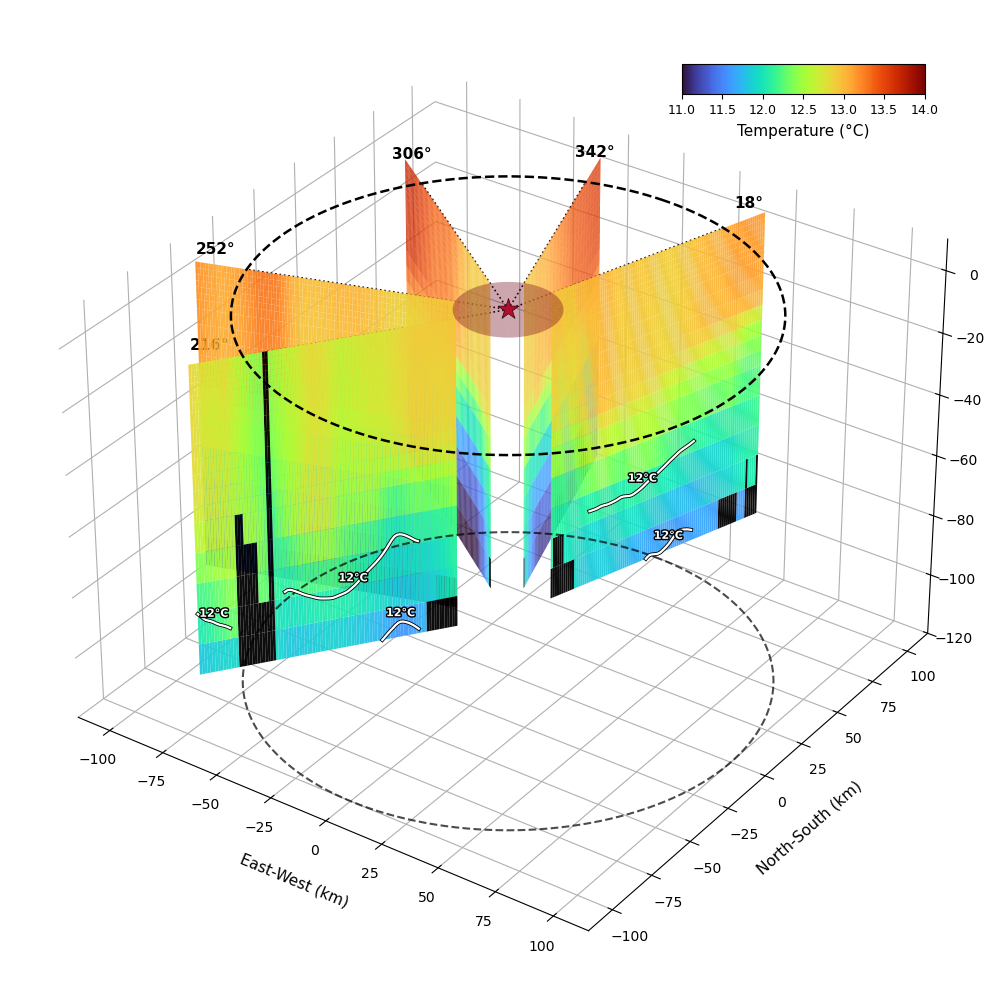

In [124]:
# ============================================================
# DATASETS
# ============================================================
angles = [18, 342, 306, 252, 216]

sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]

# Angles where thermoclines should be drawn
target_angles = [18, 216]

# ============================================================
# HELPER FUNCTION FOR CONTOUR EXTRACTION
# ============================================================
def extract_contour_segments(cs):
    segments = []
    
    # Matplotlib >= 3.8
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    # Matplotlib < 3.8
    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments

    return segments

# ============================================================
# FIGURE & AXES SETUP
# ============================================================
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

cmap = plt.cm.turbo  
norm = Normalize(vmin=11, vmax=14)

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)

# Clean up pane backgrounds
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor('w')
ax.yaxis.pane.set_edgecolor('w')
ax.zaxis.pane.set_edgecolor('w')

# Key thermocline levels (°C)
contour_levels = [11.5, 12]

# Temporary 2D figure to compute contour paths
fig_temp, ax_temp = plt.subplots()

# ============================================================
# Plot sections
# ============================================================
for ang, ds in zip(angles, sections):
    theta = np.deg2rad(ang)

    distance = ds['distance'].values + station_radius
    depth = ds['depth'][:20].values
    temp = ds['temp'][18, :20, :].values  # Shape: (depth_len, distance_len)

    D, Z = np.meshgrid(distance, depth)

    # Geographic coordinates
    X = D * np.sin(theta)
    Y = D * np.cos(theta)
    Z_mesh = -Z

    colors = cmap(norm(temp))
    colors[..., 3] = 0.95  # Light transparency

    # 1. Main surface section panel
    ax.plot_surface(
        X, Y, Z_mesh,
        facecolors=colors,
        rstride=1, cstride=1,
        linewidth=0,
        antialiased=True,
        shade=False
    )

    # 2. Add Thermoclines ONLY for 18° and 216° sections
    if ang in target_angles:
        # Smooth temperature field slightly to remove grid artifacts
        temp_smooth = gaussian_filter(temp, sigma=0.8)

        cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
        contour_segments = extract_contour_segments(cs)

        for level_val, verts in contour_segments:
            if len(verts) < 10:  # Ignore short noise segments
                continue

            d_pts = verts[:, 0]
            z_pts = verts[:, 1]

            # Convert 2D (Distance, Depth) -> 3D (X, Y, Z)
            x_pts = d_pts * np.sin(theta)
            y_pts = d_pts * np.cos(theta)

            # Draw smooth thermocline contour line
            line, = ax.plot(
                x_pts, y_pts, z_pts,
                color='white',
                lw=1.6,
                ls='-',
                zorder=30
            )
            line.set_path_effects([
                path_effects.Stroke(linewidth=2.8, foreground='black'),
                path_effects.Normal()
            ])

            # Label near the middle of each thermocline line
            mid_idx = len(x_pts) // 2
            ax.text(
                x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                f'{level_val:.0f}°C',
                color='white',
                fontsize=8,
                fontweight='bold',
                ha='center',
                va='bottom',
                zorder=35,
                path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
            )

# Close hidden helper figure
plt.close(fig_temp)

# ============================================================
# Draw Circumferences (Surface Z=0 & Bottom Z=-120)
# ============================================================
t = np.linspace(0, 2 * np.pi, 500)

# Bottom circumference around the base
ax.plot(
    R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t),
    '--k', lw=1.5, alpha=0.7, zorder=10
)

# Surface circumference
ax.plot(
    R * np.sin(t), R * np.cos(t), np.zeros_like(t),
    '--k', lw=1.8, zorder=10
)

# ============================================================
# Draw radial lines and labels
# ============================================================
for ang in angles:
    theta = np.deg2rad(ang)

    ax.plot(
        [0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0],
        color='k', lw=1.2, ls=':'
    )

    ax.text(
        112 * np.sin(theta),
        112 * np.cos(theta),
        5,
        f'{ang}°',
        fontsize=11,
        fontweight='bold',
        ha='center',
        va='center'
    )

# ============================================================
# Center Station Indicator
# ============================================================
r = np.linspace(0, station_radius, 50)
th = np.linspace(0, 2 * np.pi, 200)
RR, TT = np.meshgrid(r, th)

XX = RR * np.sin(TT)
YY = RR * np.cos(TT)
ZZ = np.zeros_like(XX)

ax.plot_surface(
    XX, YY, ZZ,
    color='crimson',
    alpha=0.4,
    linewidth=0
)

ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

# ============================================================
# Limits and Labels
# ============================================================
ax.set_xlim(-115, 115)
ax.set_ylim(-115, 115)
ax.set_zlim(-max_depth, 10)

ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)

ax.set_box_aspect((1, 1, 0.75))
ax.view_init(elev=32, azim=305)

# ============================================================
# INSET COLORBAR (Inside figure canvas)
# ============================================================
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax,
    width="25%",      # Width of the colorbar relative to axes
    height="3%",      # Height relative to axes
    loc='upper right',
    bbox_to_anchor=(-0.05, -0.05, 1, 1),
    bbox_transform=ax.transAxes
)

cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
cb.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

In [125]:
#
#

In [77]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.patheffects as path_effects
from scipy.ndimage import gaussian_filter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.cm as cm
from matplotlib.animation import FuncAnimation, FFMpegWriter

# ============================================================
# DATASETS & SETUP
# ============================================================
angles = [18, 342, 306, 252, 216]
sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]
target_angles = [18, 216]

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)
contour_levels = [11.5, 12]

cmap = plt.cm.turbo  
norm = Normalize(vmin=11, vmax=13)

# ============================================================
# HELPER FUNCTIONS
# ============================================================
def extract_contour_segments(cs):
    segments = []
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments
    return segments

# ============================================================
# ANIMATION UPDATE FUNCTION
# ============================================================
fig = plt.figure(figsize=(12, 10))

def update(frame_idx):
    fig.clear()
    
    ax = fig.add_subplot(111, projection='3d')

    # Clean up pane backgrounds
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('w')
    ax.yaxis.pane.set_edgecolor('w')
    ax.zaxis.pane.set_edgecolor('w')

    fig_temp, ax_temp = plt.subplots()

    # Plot each cross-section for the given frame_idx (0 to 30)
    for ang, ds in zip(angles, sections):
        theta = np.deg2rad(ang)

        distance = ds['distance'].values + station_radius
        depth = ds['depth'][:20].values
        
        # Dynamically sample temperature at current index: frame_idx
        temp = ds['temp'][frame_idx, :20, :].values  

        D, Z = np.meshgrid(distance, depth)

        # Geographic coordinates
        X = D * np.sin(theta)
        Y = D * np.cos(theta)
        Z_mesh = -Z

        colors = cmap(norm(temp))
        colors[..., 3] = 0.95  # Transparency

        # 1. Main surface section panel
        ax.plot_surface(
            X, Y, Z_mesh,
            facecolors=colors,
            rstride=1, cstride=1,
            linewidth=0,
            antialiased=True,
            shade=False
        )

        # 2. Add Thermoclines ONLY for target angles
        if ang in target_angles:
            temp_smooth = gaussian_filter(temp, sigma=0.8)
            cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
            contour_segments = extract_contour_segments(cs)

            for level_val, verts in contour_segments:
                if len(verts) < 10:
                    continue

                d_pts = verts[:, 0]
                z_pts = verts[:, 1]

                x_pts = d_pts * np.sin(theta)
                y_pts = d_pts * np.cos(theta)

                line, = ax.plot(
                    x_pts, y_pts, z_pts,
                    color='white', lw=1.6, ls='-', zorder=30
                )
                line.set_path_effects([
                    path_effects.Stroke(linewidth=2.8, foreground='black'),
                    path_effects.Normal()
                ])

                mid_idx = len(x_pts) // 2
                ax.text(
                    x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                    f'{level_val:.0f}°C',
                    color='white', fontsize=8, fontweight='bold',
                    ha='center', va='bottom', zorder=35,
                    path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
                )

    plt.close(fig_temp)

    # Circumferences (Surface & Bottom)
    t = np.linspace(0, 2 * np.pi, 500)
    ax.plot(R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t), '--k', lw=1.5, alpha=0.7, zorder=10)
    ax.plot(R * np.sin(t), R * np.cos(t), np.zeros_like(t), '--k', lw=1.8, zorder=10)

    # Radial lines and angle labels
    for ang in angles:
        theta = np.deg2rad(ang)
        ax.plot([0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0], color='k', lw=1.2, ls=':')
        ax.text(112 * np.sin(theta), 112 * np.cos(theta), 5, f'{ang}°', fontsize=11, fontweight='bold', ha='center', va='center')

    # Center station indicator
    r = np.linspace(0, station_radius, 50)
    th = np.linspace(0, 2 * np.pi, 200)
    RR, TT = np.meshgrid(r, th)
    XX, YY = RR * np.sin(TT), RR * np.cos(TT)
    ZZ = np.zeros_like(XX)

    ax.plot_surface(XX, YY, ZZ, color='crimson', alpha=0.4, linewidth=0)
    ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

    # Axes limits, labels, title
    ax.set_xlim(-115, 115)
    ax.set_ylim(-115, 115)
    ax.set_zlim(-max_depth, 10)
    ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
    ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
    ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)
    ax.set_title(f'Temperature Index: {frame_idx}', fontsize=14, pad=15)

    ax.set_box_aspect((1, 1, 0.75))
    ax.view_init(elev=32, azim=305)

    # Inset Colorbar
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cax = inset_axes(
        ax, width="25%", height="3%", loc='upper right',
        bbox_to_anchor=(-0.05, -0.05, 1, 1), bbox_transform=ax.transAxes
    )
    cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
    cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
    cb.ax.tick_params(labelsize=9)

# ============================================================
# CREATE & SAVE VIDEO
# ============================================================
# Frames run from 0 to 30 inclusive (31 total frames)
anim = FuncAnimation(fig, update, frames=range(31), interval=200)

# Option A: Save as MP4 (Requires ffmpeg installed on your system)
writer = FFMpegWriter(fps=5, metadata=dict(artist='Oceanography'), bitrate=1800)
anim.save('T07.mp4', writer=writer)

# Option B: Save as GIF (If ffmpeg is not installed)
# anim.save('temperature_section_evolution.gif', writer='pillow', fps=5)

plt.close()

In [126]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.patheffects as path_effects
from scipy.ndimage import gaussian_filter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.cm as cm
# Switched from FFMpegWriter to PillowWriter for GIF rendering
from matplotlib.animation import FuncAnimation, PillowWriter

# ============================================================
# DATASETS & SETUP
# ============================================================
angles = [18, 342, 306, 252, 216]
sections = [
    dsX01_1_daily,
    dsX01_2_daily,
    dsX01_3_daily,
    dsX01_4_daily,
    dsX01_5_daily,
]
target_angles = [18, 216]

station_radius = 20.0      # km
R = 100.0                  # outer boundary radius (km)
max_depth = 120.0          # max depth (m)
contour_levels = [11.5, 12]

cmap = plt.cm.turbo  
norm = Normalize(vmin=11, vmax=13)

# ============================================================
# HELPER FUNCTIONS
# ============================================================
def extract_contour_segments(cs):
    segments = []
    if hasattr(cs, 'get_paths') and callable(getattr(cs, 'get_paths')):
        for level_val, path in zip(cs.levels, cs.get_paths()):
            for poly in path.to_polygons(closed_only=False):
                if len(poly) > 0:
                    segments.append((level_val, poly))
        if segments:
            return segments

    if hasattr(cs, 'allsegs') and cs.allsegs:
        for level_val, seg_list in zip(cs.levels, cs.allsegs):
            for verts in seg_list:
                if len(verts) > 0:
                    segments.append((level_val, verts))
        if segments:
            return segments

    if hasattr(cs, 'collections'):
        for level_val, coll in zip(cs.levels, cs.collections):
            for path in coll.get_paths():
                for poly in path.to_polygons(closed_only=False):
                    if len(poly) > 0:
                        segments.append((level_val, poly))
        return segments
    return segments

# ============================================================
# ANIMATION UPDATE FUNCTION
# ============================================================
fig = plt.figure(figsize=(12, 10))

def update(frame_idx):
    fig.clear()
    
    ax = fig.add_subplot(111, projection='3d')

    # Clean up pane backgrounds
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('w')
    ax.yaxis.pane.set_edgecolor('w')
    ax.zaxis.pane.set_edgecolor('w')

    fig_temp, ax_temp = plt.subplots()

    # Plot each cross-section for the given frame_idx (0 to 30)
    for ang, ds in zip(angles, sections):
        theta = np.deg2rad(ang)

        distance = ds['distance'].values + station_radius
        depth = ds['depth'][:20].values
        
        # Dynamically sample temperature at current index: frame_idx
        temp = ds['temp'][frame_idx, :20, :].values  

        D, Z = np.meshgrid(distance, depth)

        # Geographic coordinates
        X = D * np.sin(theta)
        Y = D * np.cos(theta)
        Z_mesh = -Z

        colors = cmap(norm(temp))
        colors[..., 3] = 0.95  # Transparency

        # 1. Main surface section panel
        ax.plot_surface(
            X, Y, Z_mesh,
            facecolors=colors,
            rstride=1, cstride=1,
            linewidth=0,
            antialiased=True,
            shade=False
        )

        # 2. Add Thermoclines ONLY for target angles
        if ang in target_angles:
            temp_smooth = gaussian_filter(temp, sigma=0.8)
            cs = ax_temp.contour(distance, -depth, temp_smooth, levels=contour_levels)
            contour_segments = extract_contour_segments(cs)

            for level_val, verts in contour_segments:
                if len(verts) < 10:
                    continue

                d_pts = verts[:, 0]
                z_pts = verts[:, 1]

                x_pts = d_pts * np.sin(theta)
                y_pts = d_pts * np.cos(theta)

                line, = ax.plot(
                    x_pts, y_pts, z_pts,
                    color='white', lw=1.6, ls='-', zorder=30
                )
                line.set_path_effects([
                    path_effects.Stroke(linewidth=2.8, foreground='black'),
                    path_effects.Normal()
                ])

                mid_idx = len(x_pts) // 2
                ax.text(
                    x_pts[mid_idx], y_pts[mid_idx], z_pts[mid_idx] + 1.2,
                    f'{level_val:.0f}°C',
                    color='white', fontsize=8, fontweight='bold',
                    ha='center', va='bottom', zorder=35,
                    path_effects=[path_effects.withStroke(linewidth=2, foreground='black')]
                )

    plt.close(fig_temp)

    # Circumferences (Surface & Bottom)
    t = np.linspace(0, 2 * np.pi, 500)
    ax.plot(R * np.sin(t), R * np.cos(t), -max_depth * np.ones_like(t), '--k', lw=1.5, alpha=0.7, zorder=10)
    ax.plot(R * np.sin(t), R * np.cos(t), np.zeros_like(t), '--k', lw=1.8, zorder=10)

    # Radial lines and angle labels
    for ang in angles:
        theta = np.deg2rad(ang)
        ax.plot([0, R * np.sin(theta)], [0, R * np.cos(theta)], [0, 0], color='k', lw=1.2, ls=':')
        ax.text(112 * np.sin(theta), 112 * np.cos(theta), 5, f'{ang}°', fontsize=11, fontweight='bold', ha='center', va='center')

    # Center station indicator
    r = np.linspace(0, station_radius, 50)
    th = np.linspace(0, 2 * np.pi, 200)
    RR, TT = np.meshgrid(r, th)
    XX, YY = RR * np.sin(TT), RR * np.cos(TT)
    ZZ = np.zeros_like(XX)

    ax.plot_surface(XX, YY, ZZ, color='crimson', alpha=0.4, linewidth=0)
    ax.scatter(0, 0, 0, color='crimson', marker='*', s=250, zorder=25, edgecolor='black', lw=0.5)

    # Axes limits, labels, title
    ax.set_xlim(-115, 115)
    ax.set_ylim(-115, 115)
    ax.set_zlim(-max_depth, 10)
    ax.set_xlabel('East-West (km)', fontsize=11, labelpad=10)
    ax.set_ylabel('North-South (km)', fontsize=11, labelpad=10)
    ax.set_zlabel('Depth (m)', fontsize=11, labelpad=8)
    ax.set_title(f'Temperature Index: {frame_idx}', fontsize=14, pad=15)

    ax.set_box_aspect((1, 1, 0.75))
    ax.view_init(elev=32, azim=305)

    # Inset Colorbar
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cax = inset_axes(
        ax, width="25%", height="3%", loc='upper right',
        bbox_to_anchor=(-0.05, -0.05, 1, 1), bbox_transform=ax.transAxes
    )
    cb = plt.colorbar(sm, cax=cax, orientation='horizontal')
    cb.set_label('Temperature (°C)', fontsize=11, labelpad=5)
    cb.ax.tick_params(labelsize=9)

# ============================================================
# CREATE & SAVE GIF
# ============================================================
# Frames run from 0 to 30 inclusive (31 total frames)
anim = FuncAnimation(fig, update, frames=range(31), interval=200)

# Save as GIF using PillowWriter
writer = PillowWriter(fps=5)
anim.save('T07.gif', writer=writer)

plt.close()

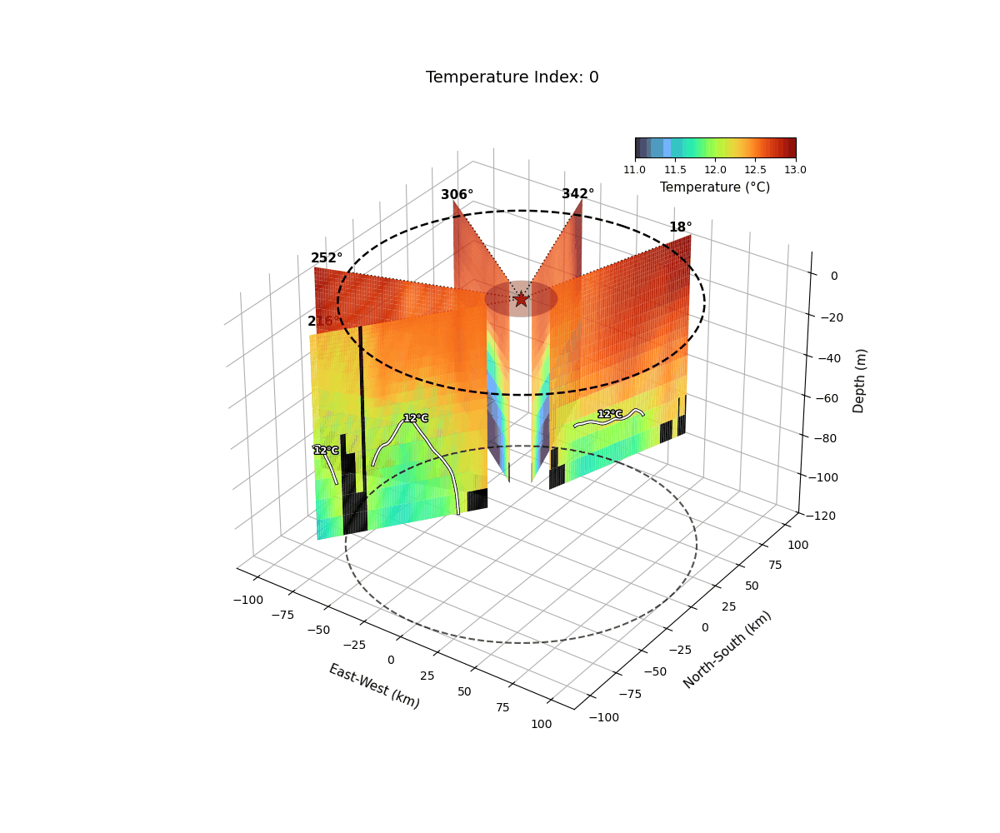

In [127]:
from IPython.display import Image, display

# Display the local GIF file in the notebook output
display(Image(filename='T07.gif'))

In [ ]:
#